# 03 · Modelos de referencia y pruebas iniciales (tareas 2.6 y 2.7)

**Proyecto 1 · Innovación Tecnológica con IA · Grupo 4**

Comparamos, con la **misma partición por grabación** (70/15/15, semilla 42), la clase mayoritaria, cuatro clasificadores clásicos sobre estadísticas de MFCC y la CNN base sobre espectrogramas Mel, y ponemos a prueba las hipótesis H2, H3 y H4 del [reporte 2](../docs/reporte_entrega_2.md).

Los modelos clásicos se entrenan aquí mismo (tardan segundos). Las corridas de la CNN se entrenan con `python -m src.main train` (ver los comandos al final) y aquí leemos sus resultados.

In [1]:
import os, sys, json
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent   # carpeta entrega_2/
os.chdir(ROOT); sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
from IPython.display import Image, display

pd.set_option("display.max_rows", 60, "display.width", 200, "display.float_format", "{:.3f}".format)
RESULTS, FIGURES, PROCESSED = ROOT / "experiments/results", ROOT / "docs/figuras", ROOT / "data/processed"


## 1. Partición

Todas las ventanas de una grabación quedan en la misma partición.

In [2]:
from src.data.dataset import WINDOW_SPLIT_COLUMN
from src.models.classical import MODEL_TITLES, evaluate_classical, load_mfcc_dataset

index, features = load_mfcc_dataset(PROCESSED)
assert {"split", WINDOW_SPLIT_COLUMN} <= set(index.columns), "Ejecute primero `python -m src.main baselines` con ambas particiones"
assert (index.groupby("recording_id")["split"].nunique() == 1).all()

sizes = pd.DataFrame({
    "grabaciones": index.groupby("split")["recording_id"].nunique(),
    "ventanas": index.groupby("split").size(),
}).loc[["train", "val", "test"]]
sizes["ventanas_pct"] = (100 * sizes["ventanas"] / sizes["ventanas"].sum()).round(1)
display(sizes)
pd.crosstab(index["label"], index["split"])[["train", "val", "test"]]

,grabaciones,ventanas,ventanas_pct
split,,,
train,585,7972,71.400
val,118,1593,14.300
test,119,1594,14.300


split,train,val,test
label,,,
Cyphorhinus_thoracicus,663,133,132
Henicorhina_leucophrys,503,103,102
Henicorhina_leucosticta,577,117,116
Myadestes_ralloides,567,111,111
Odontophorus_hyperythrus,421,84,84
Ortalis_columbiana,620,121,124
Pheugopedius_mystacalis,534,107,107
Rupornis_magnirostris,594,119,119
Scytalopus_alvarezlopezi,483,94,98


## 2. Modelos clásicos sobre estadísticas de MFCC

Cada ventana se resume en 80 valores: media y desviación estándar en el tiempo de 20 MFCC y de sus deltas.

In [3]:
METRICS = ["accuracy", "balanced_accuracy", "f1_macro", "top3_accuracy"]
classical, predictions = evaluate_classical(features, index, "split")
classical_test = classical[classical["conjunto"] == "test"].set_index("modelo")[METRICS]
classical_test.rename(index=MODEL_TITLES)

2026-11-14 13:05:22 | INFO | classical | mayoritaria | F1 macro en prueba: 0.010


2026-11-14 13:05:25 | INFO | classical | regresion_logistica | F1 macro en prueba: 0.567


2026-11-14 13:05:34 | INFO | classical | svm | F1 macro en prueba: 0.623


2026-11-14 13:05:39 | INFO | classical | bosque_aleatorio | F1 macro en prueba: 0.608


2026-11-14 13:06:14 | INFO | classical | potenciacion_gradiente | F1 macro en prueba: 0.590


,accuracy,balanced_accuracy,f1_macro,top3_accuracy
modelo,,,,
Clase mayoritaria,0.083,0.067,0.010,0.205
Regresión logística (MFCC),0.578,0.577,0.567,0.769
SVM RBF (MFCC),0.620,0.614,0.623,0.802
Bosque aleatorio (MFCC),0.610,0.605,0.608,0.794
Potenciación de gradiente (MFCC),0.593,0.591,0.590,0.803


## 3. CNN base sobre espectrogramas Mel

Cuatro bloques convolucionales, ≈ 1,2 millones de parámetros, entrenada desde cero con pesos por clase y aumentación tipo SpecAugment.

In [4]:
def cnn_metrics(run: str) -> dict:
    return json.loads((RESULTS / f"{run}_test_metricas.json").read_text(encoding="utf-8"))

def cnn_summary(run: str) -> dict:
    return json.loads((RESULTS / f"{run}_train_summary.json").read_text(encoding="utf-8"))

RUNS = {"cnn_base": "CNN base (con aumentación)", "cnn_sin_aug": "CNN sin aumentación", "cnn_split_ventana": "CNN, partición por ventana"}
runs = pd.DataFrame({title: {**{m: cnn_metrics(run)[m] for m in METRICS},
                             "mejor_epoca": cnn_summary(run)["best_epoch"], "epocas": cnn_summary(run)["epochs_run"]}
                     for run, title in RUNS.items()}).T
runs

,accuracy,balanced_accuracy,f1_macro,top3_accuracy,mejor_epoca,epocas
CNN base (con aumentación),0.734,0.730,0.735,0.871,10.000,12.000
CNN sin aumentación,0.723,0.721,0.720,0.865,11.000,12.000
"CNN, partición por ventana",0.856,0.857,0.857,0.939,12.000,12.000


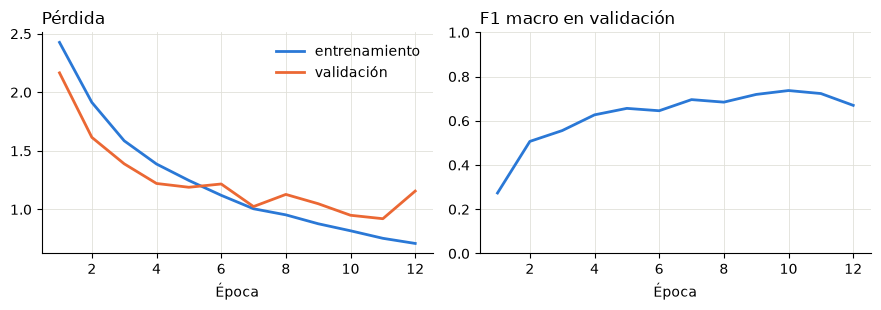

In [5]:
import matplotlib.pyplot as plt

history = pd.read_csv(RESULTS / "cnn_base_history.csv")
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
axes[0].plot(history["epoch"], history["train_loss"], color="#2a78d6", linewidth=2, label="entrenamiento")
axes[0].plot(history["epoch"], history["val_loss"], color="#eb6834", linewidth=2, label="validación")
axes[0].set_title("Pérdida", loc="left"); axes[0].set_xlabel("Época"); axes[0].legend(frameon=False)
axes[1].plot(history["epoch"], history["f1_macro"], color="#2a78d6", linewidth=2)
axes[1].set_title("F1 macro en validación", loc="left"); axes[1].set_xlabel("Época"); axes[1].set_ylim(0, 1)
for ax in axes:
    ax.grid(color="#e1e0d9", linewidth=0.6); ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); fig.savefig(FIGURES / "cnn_base_curvas.png", dpi=130, bbox_inches="tight"); plt.show()

## 4. Tabla comparativa (conjunto de prueba, partición por grabación)

In [6]:
table = pd.concat([classical_test.rename(index=MODEL_TITLES), runs.loc[["CNN base (con aumentación)"], METRICS].rename(index={"CNN base (con aumentación)": "CNN base (espectrogramas Mel)"})])
table.columns = ["Exactitud", "Exactitud balanceada", "F1 macro", "Top-3"]
table.to_csv(RESULTS / "comparacion_modelos_test.csv")
table.astype(float).round(3)

,Exactitud,Exactitud balanceada,F1 macro,Top-3
Clase mayoritaria,0.083,0.067,0.010,0.205
Regresión logística (MFCC),0.578,0.577,0.567,0.769
SVM RBF (MFCC),0.620,0.614,0.623,0.802
Bosque aleatorio (MFCC),0.610,0.605,0.608,0.794
Potenciación de gradiente (MFCC),0.593,0.591,0.590,0.803
CNN base (espectrogramas Mel),0.734,0.730,0.735,0.871


### Matriz de confusión y F1 por especie de la CNN base

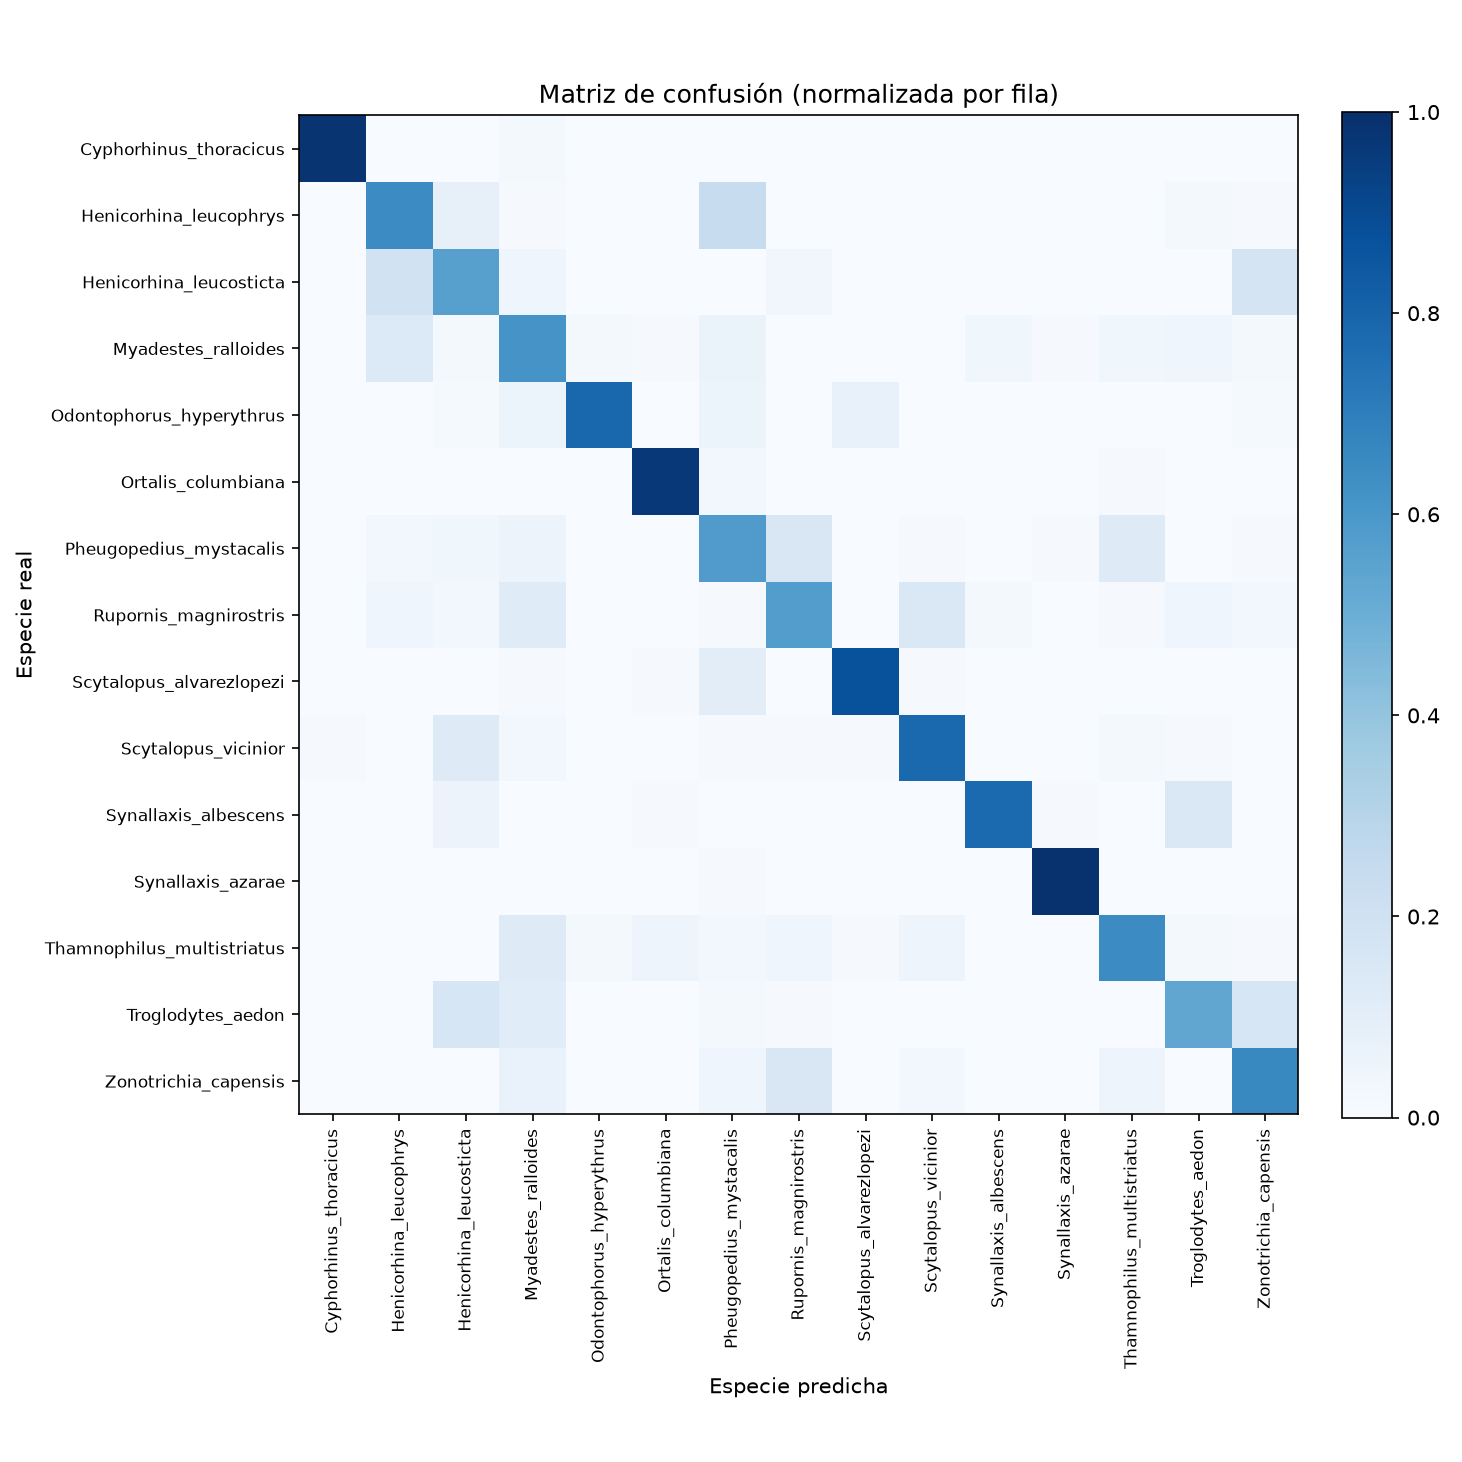

,precision,recall,f1-score,support,ventanas_train
Pheugopedius_mystacalis,0.504,0.579,0.539,107.000,534
Myadestes_ralloides,0.500,0.613,0.551,111.000,567
Henicorhina_leucosticta,0.556,0.560,0.558,116.000,577
Troglodytes_aedon,0.625,0.532,0.575,94.000,474
Rupornis_magnirostris,0.624,0.571,0.596,119.000,594
Henicorhina_leucophrys,0.595,0.647,0.620,102.000,503
Zonotrichia_capensis,0.600,0.660,0.629,100.000,503
Thamnophilus_multistriatus,0.711,0.646,0.677,99.000,496
Scytalopus_vicinior,0.755,0.783,0.769,106.000,527
Synallaxis_albescens,0.930,0.777,0.847,103.000,516


In [7]:
display(Image(RESULTS / "cnn_base_test_matriz_confusion.png", width=720))
per_species = pd.read_csv(RESULTS / "cnn_base_test_por_especie.csv", index_col=0)
per_species = per_species[per_species.index.isin(index["label"].unique())]
per_species["ventanas_train"] = index[index["split"] == "train"].groupby("label").size()
per_species.sort_values("f1-score")[["precision", "recall", "f1-score", "support", "ventanas_train"]]

## 5. Hipótesis

### H4 · ¿La CNN sobre espectrogramas supera a los clasificadores clásicos sobre MFCC?

In [8]:
best_classical = classical_test["f1_macro"].drop("mayoritaria").idxmax()
print(f"Mejor clásico: {MODEL_TITLES[best_classical]} -> F1 macro {classical_test.loc[best_classical, 'f1_macro']:.3f}")
print(f"CNN base -> F1 macro {runs.loc['CNN base (con aumentación)', 'f1_macro']:.3f}")

Mejor clásico: SVM RBF (MFCC) -> F1 macro 0.623
CNN base -> F1 macro 0.735


### H2 · ¿La aumentación mejora las especies con menos datos?

Comparamos el F1 por especie de la CNN con y sin aumentación, separando el tercio de especies con menos ventanas de entrenamiento.

In [9]:
def f1_by_species(run: str) -> pd.Series:
    report = pd.read_csv(RESULTS / f"{run}_test_por_especie.csv", index_col=0)
    return report.loc[report.index.isin(index["label"].unique()), "f1-score"]

h2 = pd.DataFrame({"ventanas_train": index[index["split"] == "train"].groupby("label").size(),
                   "f1_con_aug": f1_by_species("cnn_base"), "f1_sin_aug": f1_by_species("cnn_sin_aug")}).sort_values("ventanas_train")
h2["diferencia"] = h2["f1_con_aug"] - h2["f1_sin_aug"]
third = len(h2) // 3
h2["grupo"] = ["tercio con menos datos"] * third + ["resto"] * (len(h2) - third)
display(h2)
h2_summary = h2.groupby("grupo")[["f1_con_aug", "f1_sin_aug", "diferencia"]].mean()
h2_summary.loc["todas (F1 macro)"] = h2[["f1_con_aug", "f1_sin_aug", "diferencia"]].mean()
h2.to_csv(RESULTS / "h2_aumentacion_por_especie.csv")
h2_summary

,ventanas_train,f1_con_aug,f1_sin_aug,diferencia,grupo
Odontophorus_hyperythrus,421,0.857,0.795,0.062,tercio con menos datos
Troglodytes_aedon,474,0.575,0.655,-0.081,tercio con menos datos
Scytalopus_alvarezlopezi,483,0.890,0.810,0.080,tercio con menos datos
Synallaxis_azarae,494,0.980,0.970,0.010,tercio con menos datos
Thamnophilus_multistriatus,496,0.677,0.741,-0.063,tercio con menos datos
Henicorhina_leucophrys,503,0.620,0.523,0.097,resto
Zonotrichia_capensis,503,0.629,0.671,-0.042,resto
Synallaxis_albescens,516,0.847,0.792,0.055,resto
Scytalopus_vicinior,527,0.769,0.588,0.181,resto
Pheugopedius_mystacalis,534,0.539,0.608,-0.069,resto


,f1_con_aug,f1_sin_aug,diferencia
grupo,,,
resto,0.704,0.683,0.022
tercio con menos datos,0.796,0.794,0.002
todas (F1 macro),0.735,0.720,0.015


### H3 · ¿Particionar por ventana sobrestima el desempeño?

Repetimos el entrenamiento con una partición al azar por ventana (`split_ventana`), en la que ventanas de una misma grabación caen en entrenamiento y en prueba, y comparamos con la partición por grabación.

In [10]:
by_window, _ = evaluate_classical(features, index, WINDOW_SPLIT_COLUMN)
window_test = by_window[by_window["conjunto"] == "test"].set_index("modelo")["f1_macro"]
h3 = pd.DataFrame({"F1 por grabación": classical_test["f1_macro"], "F1 por ventana": window_test}).drop("mayoritaria").rename(index=MODEL_TITLES)
h3.loc["CNN base (espectrogramas Mel)"] = [cnn_metrics("cnn_base")["f1_macro"], cnn_metrics("cnn_split_ventana")["f1_macro"]]
h3["sobrestimación"] = h3["F1 por ventana"] - h3["F1 por grabación"]
h3.to_csv(RESULTS / "h3_particion.csv")
h3

2026-11-14 13:06:15 | INFO | classical | mayoritaria | F1 macro en prueba: 0.010


2026-11-14 13:06:16 | INFO | classical | regresion_logistica | F1 macro en prueba: 0.707


2026-11-14 13:06:19 | INFO | classical | svm | F1 macro en prueba: 0.886


2026-11-14 13:06:22 | INFO | classical | bosque_aleatorio | F1 macro en prueba: 0.887


2026-11-14 13:06:49 | INFO | classical | potenciacion_gradiente | F1 macro en prueba: 0.930


,F1 por grabación,F1 por ventana,sobrestimación
modelo,,,
Regresión logística (MFCC),0.567,0.707,0.140
SVM RBF (MFCC),0.623,0.886,0.263
Bosque aleatorio (MFCC),0.608,0.887,0.279
Potenciación de gradiente (MFCC),0.590,0.930,0.340
CNN base (espectrogramas Mel),0.735,0.857,0.122


## 6. Conclusiones de los modelos de referencia

1. **Ya tenemos un piso de referencia.** Con la partición por grabación, el mejor clasificador clásico (SVM sobre estadísticas de MFCC) alcanza un F1 macro de 0,62 en prueba y la CNN base liviana, 0,73 por ventana (intervalo de confianza del 95 %: 0,66 a 0,78) y 0,82 por grabación (0,74 a 0,87); exactitud top-3 de 0,87. El azar está en 0,07 y la meta aproximada del proyecto en 0,70.
2. **H4 recibe apoyo.** La CNN sobre espectrogramas supera al mejor clásico por 0,11 de F1 macro, más del criterio de 0,05: conservar la estructura tiempo-frecuencia aporta información que el resumen de MFCC pierde.
3. **H3 recibe apoyo, con todos los modelos.** Con la partición al azar por ventana el F1 macro sube entre 0,12 (CNN) y 0,34 (potenciación de gradiente). Esa diferencia no es desempeño real: es fuga de información entre ventanas de una misma grabación. Solo reportamos desempeño con la partición por grabación.
4. **H2 no recibe apoyo con esta evidencia.** En el tercio de especies con menos ventanas de entrenamiento la aumentación casi no cambia el F1 medio (0,796 frente a 0,794; criterio: 0,02). En el conjunto de todas las especies el F1 macro sube 0,015, una diferencia menor que la variación entre épocas de una misma corrida. Además, nuestras especies están casi balanceadas (421 a 663 ventanas de entrenamiento), así que el contraste entre "pocos" y "muchos" datos es débil.
5. **Las especies difíciles coinciden con las del análisis exploratorio.** Las de menor F1 con la CNN son *P. mystacalis* (0,54), *M. ralloides* (0,55), *H. leucosticta* (0,56), *T. aedon* (0,57) y *R. magnirostris* (0,60); las confusiones más frecuentes ocurren entre los cucaracheros (*Henicorhina*, *Pheugopedius*, *Troglodytes*) y con *Z. capensis*. Las de canto más estereotipado (*C. thoracicus*, *S. azarae*, *O. columbiana*) superan 0,95.
6. **Limitaciones.** Una sola semilla, un solo conjunto de prueba (119 grabaciones) y una CNN liviana entrenada 12 épocas en CPU, que aún no converge: la validación oscila entre épocas. Tratamos las diferencias pequeñas como indicios, no como conclusiones.
